# Week 2 homework

Data: 2024 American Time Use Survey, US Bureau of Labor Statistics.
Each row contains an estimated average or difference in daily working hours,
with confidence limits. Variable definitions are in `data/README.md`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("data/working_time.csv")
data.head()

,day_type,measure,series,estimate_hours,ci_low_hours,ci_high_hours
0,Weekdays,Job-related work,Men,7.857500,7.558580,8.156420
1,Weekdays,Household and care work,Men,1.838531,1.623811,2.053251
2,Weekdays,Combined work,Men,9.696031,9.368479,10.023582
3,Weekdays,Job-related work,Women,6.741170,6.357812,7.124529
4,Weekdays,Household and care work,Women,2.635240,2.440795,2.829685


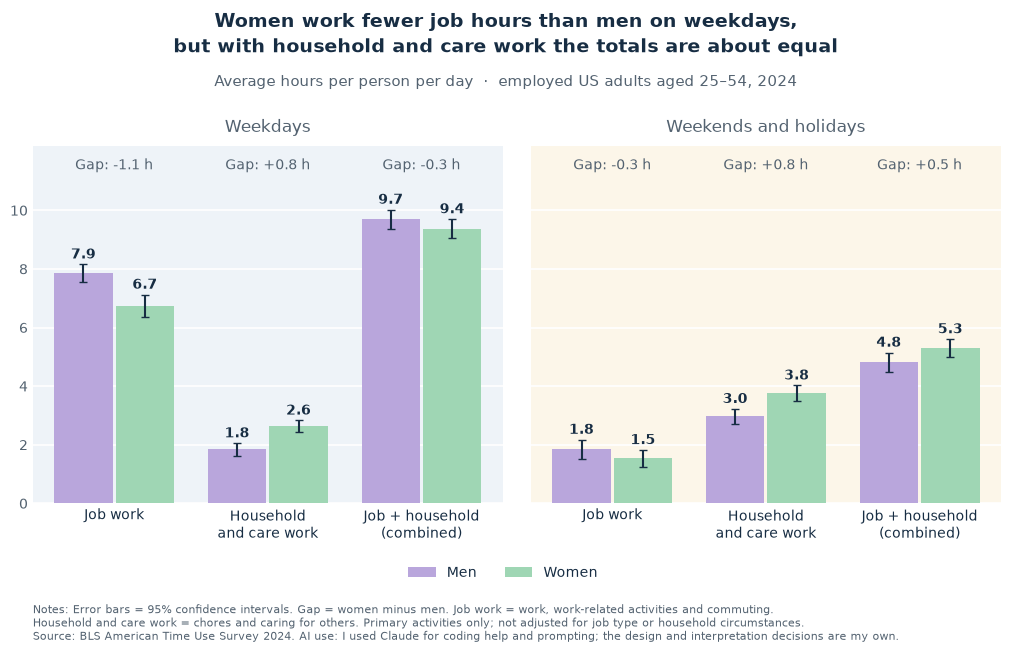

In [2]:
INK, GRAY = "#172d43", "#536270"
plt.rcParams.update({"font.family": "DejaVu Sans", "text.color": INK, "xtick.color": INK, "ytick.color": GRAY})

measures = ["Job-related work", "Household and care work", "Combined work"]
labels = ["Job work", "Household\nand care work", "Job + household\n(combined)"]

fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), sharey=True, gridspec_kw={"wspace": 0.06})
for ax, day, bg in zip(axes, ["Weekdays", "Weekends and holidays"], ["#eef3f8", "#fcf6e9"]):
    d = data[data.day_type == day].set_index(["measure", "series"])
    ax.set_facecolor(bg)
    for i, m in enumerate(measures):
        for shift, sex, color in [(-0.2, "Men", "#b9a6dc"), (0.2, "Women", "#9fd6b4")]:
            r = d.loc[(m, sex)]
            ax.bar(i + shift, r.estimate_hours, 0.38, color=color, label=sex if i == 0 else None)
            ax.errorbar(i + shift, r.estimate_hours, color=INK, capsize=3,   # 95% CI
                        yerr=[[r.estimate_hours - r.ci_low_hours], [r.ci_high_hours - r.estimate_hours]])
            ax.text(i + shift, r.ci_high_hours + 0.2, f"{r.estimate_hours:.1f}", ha="center", fontweight="bold")
        gap = d.loc[(m, "Women minus men"), "estimate_hours"]
        ax.text(i, 11.4, f"Gap: {gap:+.1f} h", ha="center", color=GRAY)
    ax.set_title(day, color=GRAY, pad=10)
    ax.set_xticks(range(3), labels)
    ax.set_ylim(0, 12.2)
    ax.set_yticks(range(0, 11, 2))
    ax.grid(axis="y", color="white", lw=1.2)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    ax.spines[:].set_visible(False)

axes[0].legend(loc="upper center", bbox_to_anchor=(1.0, -0.14), ncol=2, frameon=False)
fig.suptitle("Women work fewer job hours than men on weekdays,\nbut with household and care work the totals are about equal",
             fontsize=14, fontweight="bold", linespacing=1.3)
fig.text(0.5, 0.862, "Average hours per person per day  ·  employed US adults aged 25–54, 2024",
         fontsize=11, color=GRAY, ha="center")
fig.text(0.07, 0.01,
         "Notes: Error bars = 95% confidence intervals. Gap = women minus men. Job work = work, work-related activities and commuting.\n"
         "Household and care work = chores and caring for others. Primary activities only; not adjusted for job type or household circumstances.\n"
         "Source: BLS American Time Use Survey 2024. AI use: I used Claude for coding help and prompting; the design and interpretation decisions are my own.",
         fontsize=8, color=GRAY, linespacing=1.2)
fig.subplots_adjust(left=0.07, right=0.95, top=0.77, bottom=0.22)
fig.savefig("working_time_figure.png", dpi=300) 
plt.show()